In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
from pathlib import Path

from bioio import BioImage

# data_path = Path("/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261007 Repeat/Experiment-152.czi")
channels = ["PRRT","A1","PSD","RIM"]
data_path = Path("/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261020 Repeat/Experiment-358.czi")
image = BioImage(data_path)
data = image.xarray_dask_data.assign_coords({"C":channels})

In [ ]:
import napari

v = napari.Viewer()
v.add_image(image.data, channel_axis=1,name=channels)

[<Image layer 'Image' at 0x7c8fe81538c0>,
 <Image layer 'Image [1]' at 0x7c8fcd18fc50>,
 <Image layer 'Image [2]' at 0x7c8fcd18f250>,
 <Image layer 'Image [3]' at 0x7c8fca2a4410>]

# 2. Drift correction

In [105]:
from prrt_clustering import correct_z_drift

shift, stabilized = correct_z_drift(data)

Text(0, 0.5, 'shift [um]')

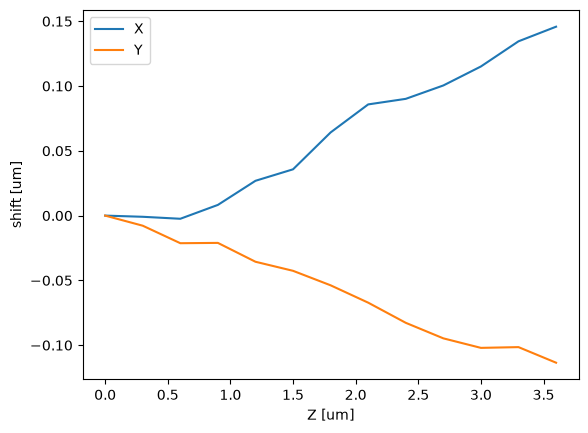

In [5]:
import matplotlib.pyplot as plt

plt.plot(shift.reset_index()["Z"], shift["DX [um]"])
plt.plot(shift.reset_index()["Z"], shift["DY [um]"])
plt.legend(["X","Y"])
plt.xlabel("Z [um]")
plt.ylabel("shift [um]")

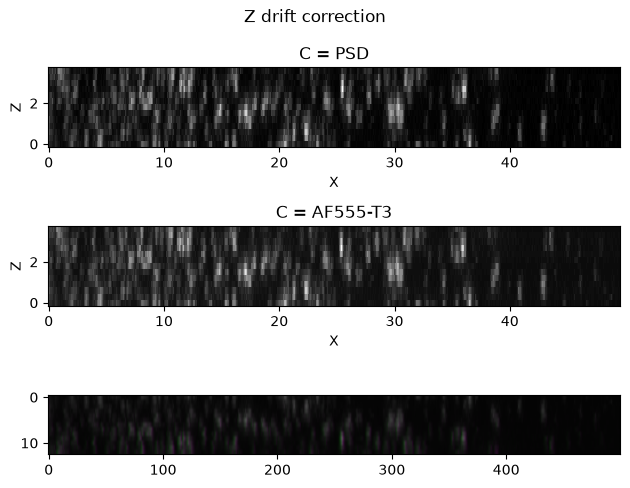

In [104]:
import matplotlib.pyplot as plt
import numpy as np

n = 500
a = data[0,2,:,:n,:n].max(axis=1)
b = stabilized[0,2,:,:n,:n].max(axis=1)
plt.subplot(311)
a.plot(add_colorbar=False,cmap='gray')
plt.subplot(312)
b.plot(add_colorbar=False,cmap='gray')
plt.subplot(313)
plt.imshow(np.stack([a,b,a],axis=2),aspect=4)
plt.suptitle('Z drift correction')
plt.tight_layout()


In [ ]:
# import napari
# v = napari.Viewer()
# v.add_image(image.data, channel_axis=1)
# v.add_image(stabilized.data[0,0,:,:100,:100], channel_axis=1)

## 2. Spot detection

- Detect spots in all channels

{'C': 'PRRT'}
{'C': 'A1'}
{'C': 'PSD'}
{'C': 'RIM'}


(<Figure size 2000x2000 with 4 Axes>,
 array([<Axes: title={'center': 'A1'}>, <Axes: title={'center': 'PRRT'}>,
        <Axes: title={'center': 'PSD'}>, <Axes: title={'center': 'RIM'}>],
       dtype=object))

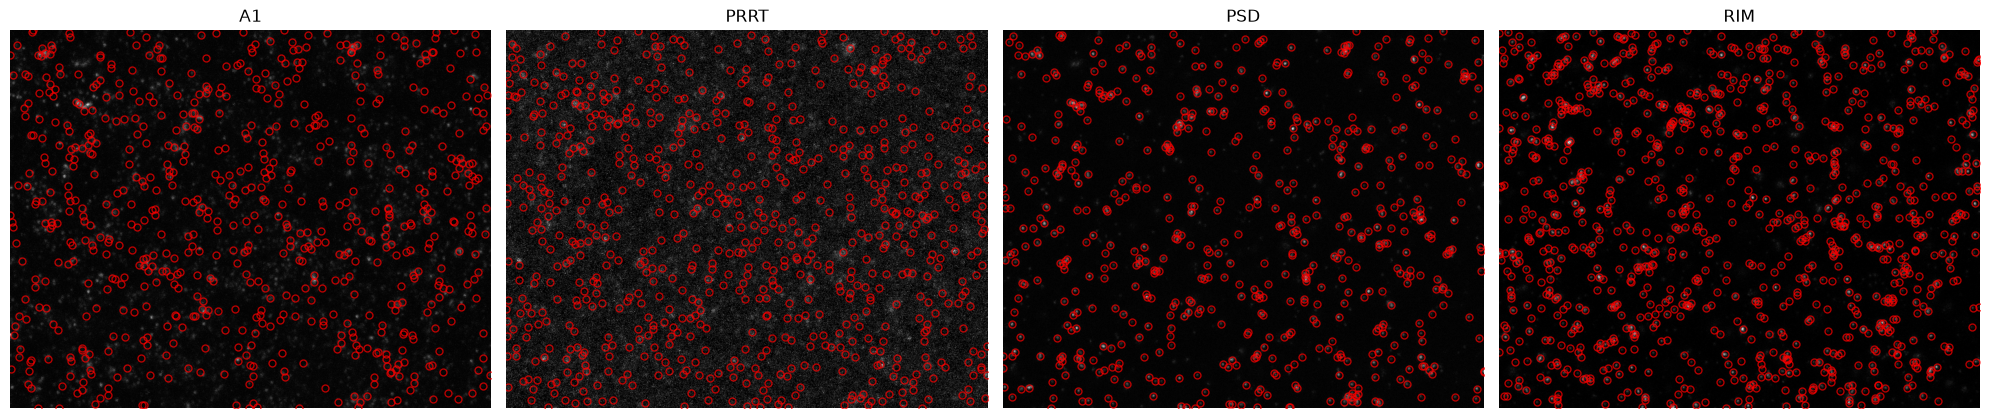

In [198]:
import matplotlib.pyplot as plt
import numpy as np

from prrt_clustering import detect_puncta, plot_data, plot_points

tmp = stabilized[0,:,:,250:800,800:1500]

points = detect_puncta(tmp, scale_um=[0.2,0.4,0.1,0.1], specificity=[3,3,8,6])

fig = plt.figure(figsize=(20,20))
fig, axes = plot_data(tmp,split=True,fig=fig)
plot_points(points, ms=10, split=True, axes=axes)


In [ ]:
import napari

v = napari.Viewer(ndisplay=3)
# v.add_image(image.data, channel_axis=1)
vx = np.array([(tmp[a][1].values - tmp[a][0].values) for a in ["Z", "Y", "X"]])
o = np.array([tmp[a][0].values for a in ["Z", "Y", "X"]])
# v.add_image(tmp,scale=vx,translate=o, channel_axis=0,name=channels)
fcol = {"PRRT":"magenta","A1":"red","PSD": "green","RIM":"yellow"}
for n,pts in points.groupby("C"):
    v.add_image(tmp.sel(C=n) ,scale=vx,translate=o,name=n,colormap=fcol[n])
    v.add_points(pts[["Z","Y","X"]], size=0.5, name=n,face_color=fcol[n])

Traceback (most recent call last):
  File "/home/jeromeb/work/code/greger/xinyao/prrt_clustering/.venv/lib/python3.13/site-packages/vispy/util/event.py", line 469, in _invoke_callback
    cb(event)
    ~~^^^^^^^
  File "/home/jeromeb/work/code/greger/xinyao/prrt_clustering/.venv/lib/python3.13/site-packages/napari/_vispy/camera.py", line 284, in viewbox_mouse_event
    super().viewbox_mouse_event(event)
    ~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^
  File "/home/jeromeb/work/code/greger/xinyao/prrt_clustering/.venv/lib/python3.13/site-packages/vispy/scene/cameras/perspective.py", line 238, in viewbox_mouse_event
    self._update_rotation(event)
    ~~~~~~~~~~~~~~~~~~~~~^^^^^^^
  File "/home/jeromeb/work/code/greger/xinyao/prrt_clustering/.venv/lib/python3.13/site-packages/vispy/scene/cameras/arcball.py", line 64, in _update_rotation
    Quaternion(*_arcball(self._event_value, wh)) *
                ~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/jeromeb/work/code/greger/xinyao/prrt_clustering/.

## 3. Clustering
Cluster points to identify potential synapses.

In [208]:
from prrt_clustering import clean_points_besag, cluster_dbscan, plot_clusters

clean = clean_points_besag(points[points["C"].isin(["PSD","RIM"])],2,10,1.1)
clean = clean[clean["noise"]==False]  # noqa: E712
cpoints,clusters = cluster_dbscan(clean, 1, 1)
cpoints = cpoints[cpoints["noise"]==False]
fig = plt.figure(figsize=(10,10))
fig,axes = plot_data(tmp,split=True,fig=fig)
# plot_points(points,ms=5,split=True,axes=axes)
# plot_points(clean,ms=2,split=True,axes=axes)
plot_clusters(cpoints,ms=10,split=True,axes=axes)

KeyError: "['intensity'] not in index"

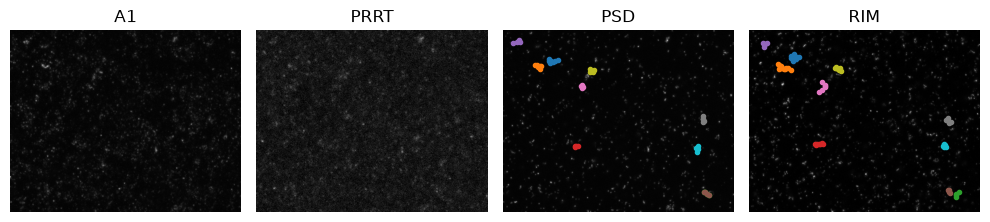

In [209]:
from prrt_clustering import pair_cluster, cluster_dbscan

def find_synapses(points, channels=["RIM","PSD"]):
    pts = points[points["C"].isin(channels)]
    pts, clusters = cluster_dbscan(pts, 1.5, 4)
    synapses = pair_cluster(clusters, channels, 2)
    return pts, clusters, synapses

spoints, clusters, synapses = find_synapses(points)
# points = spoints[spoints["noise"]==False]
fig = plt.figure(figsize=(10,10))
fig,axes = plot_data(tmp, split=True,fig=fig)
# plot_clusters(spoints[spoints["noise"]==False],ms=10,split=True,axes=axes)
for s in synapses.iloc:
    a = spoints[(spoints["C"]=="RIM") & (spoints["cluster"]==s["RIM"])]
    axes[3].plot(a["X"],a["Y"],'.')
    b = spoints[(spoints["C"]=="PSD") & (spoints["cluster"]==s["PSD"])]
    axes[2].plot(b["X"],b["Y"],'.')